### Simple Visualisations

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from util.data_aquisition import generate
from util.data_frame import get_data_frame
import math

#### Load data

In [2]:
data = generate()

Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/play_off/2016-2017
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2016-2017
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/play_off/2017-2018
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2017-2018
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/play_off/2018-2019
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2018-2019
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/play_off/2019-2020
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2019-2020
Data is available on your system. Will be loaded from: /

In [3]:
df = get_data_frame(data)

In [4]:
df.head()

,Game_ID,Game_Type,Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Shoot_Type,Time,Period,Period_Time,Team_Attack,Power_Game,Empty_Net,Shooters_scorer,Goalies,X_Coordinate,Y_Coordinate
0,2016030185,P,4,Edmonton Oilers,left,San Jose Sharks,Shot,Backhand,2017-04-21T02:45:20Z,1,00:19,San Jose Sharks,NaN,NaN,Joe Pavelski,Cam Talbot,-56.0,23.0
1,2016030185,P,9,Edmonton Oilers,left,San Jose Sharks,Shot,Wrist Shot,2017-04-21T02:45:40Z,1,00:39,Edmonton Oilers,NaN,NaN,Milan Lucic,Martin Jones,59.0,15.0
2,2016030185,P,11,Edmonton Oilers,left,San Jose Sharks,Shot,Slap Shot,2017-04-21T02:46:01Z,1,01:00,San Jose Sharks,NaN,NaN,Jannik Hansen,Cam Talbot,-34.0,-30.0
3,2016030185,P,17,Edmonton Oilers,left,San Jose Sharks,Shot,Snap Shot,2017-04-21T02:47:55Z,1,02:03,San Jose Sharks,NaN,NaN,Justin Braun,Cam Talbot,-33.0,26.0
4,2016030185,P,18,Edmonton Oilers,left,San Jose Sharks,Shot,Snap Shot,2017-04-21T02:48:04Z,1,02:12,Edmonton Oilers,NaN,NaN,Oscar Klefbom,Martin Jones,45.0,19.0


#### 1) Shot type comparaison

In [5]:
SEASON = 2016 #Choose the seaoson

In [6]:
df1=df[df.Game_ID.map(lambda id: str(id).startswith(str(SEASON)))]

/Users/nassimwalha/opt/miniconda3/envs/project/lib/python3.10/site-packages/seaborn/distributions.py:269: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  baselines.iloc[:, cols] = (curves
/var/folders/yp/s64kzpxd3k95zytpqbx3y1tw0000gn/T/ipykernel_17426/1308447084.py:3: UserWarning: FixedFormatter should only be used together with FixedLocator
  g.set_xticklabels(g.get_xticklabels(), rotation=40, ha="right")


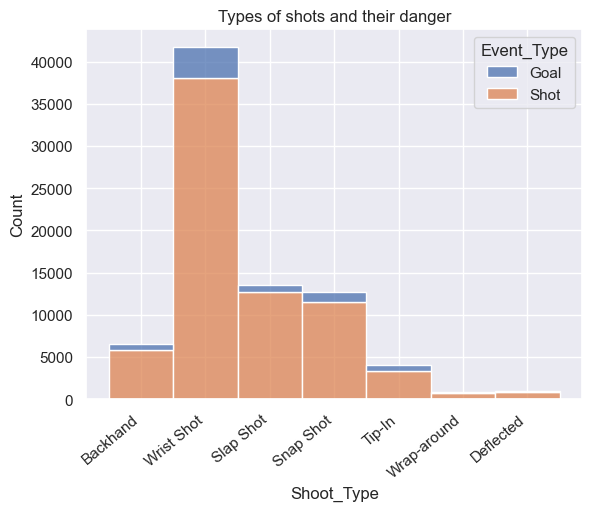

In [7]:
sns.set_theme()
g = sns.histplot(df1, x="Shoot_Type", hue="Event_Type", multiple="stack", hue_order=['Goal', 'Shot'])
g.set_xticklabels(g.get_xticklabels(), rotation=40, ha="right")
plt.title(f"Types of shots and their danger for season {SEASON}.")
plt.show(g)

In [8]:
#This function takes a series of event_types (possible types: Shot or Goal) and returns the ratio of Goals.
def calculate_probability(event_types):
    counts = event_types.value_counts(normalize=True)
    if 'Goal' in counts:
        return counts['Goal']
    return 0.0 #If there are no Goals then P('Goal')=0

In [9]:
#What's the most dangerous shot?

df1.groupby(by='Shoot_Type').agg(goal_probability=pd.NamedAgg(column="Event_Type", aggfunc= calculate_probability))

,goal_probability
Shoot_Type,
Backhand,0.106402
Deflected,0.198010
Slap Shot,0.061317
Snap Shot,0.092044
Tip-In,0.179146
Wrap-around,0.083037
Wrist Shot,0.088195


Deflected shot is the most dangerous

#### 2) Change of a goal depending on distance

Our approach will be to make a barplot where each bar represents a bin of possible distances of width WIDTH, and its height will represent the probability that a Shot taken from that range of distance will be a Goal. The binning here is important since we want to group the shots by distance, but distance is a float variable so groupping by it directly doesn't make sense. That's why we convert it into categories (bins) that still reflect the magnitude of the distance

In [10]:
#First, we need to calculate the distance to the opponent's goal based on the coordinates
#For that we define a dictionary containing the cordinates of both Goals
GOALS = {"right": (89,0),"left": (-89,0)}
#We use the dictionary inside the following function which will be passed to pd.DataFrame.apply to create the
#'Distance' column.
def calc_distance(equipe, home, home_current_rinkside, x, y):
    is_home = equipe == home
    if home_current_rinkside == np.nan: #Some data lack indication of who's on the right rink and who's on the left.
        opponent_goal = "right" if x>=0 else "left" #Just assume opponent's goal is the closest one
    else: #If we know who's on the right and who's on the left we can determine the opponent's goal.
        opponent_goal = "right" if (is_home and home_current_rinkside=="left") \
                               or (not is_home and home_current_rinkside=="right") else "left"
    opponent_goal_coordinates = GOALS[opponent_goal] #Now we got the coordinated of opponent's goal
    #Return the distance between current position and opponent's goal
    return np.sqrt((x-opponent_goal_coordinates[0])**2+(y-opponent_goal_coordinates[1])**2)

In [11]:
#Create 'Distance' column
df['Distance']=df.apply(lambda x: calc_distance(x['Team_Attack'],x['Home_Team'],x['Home_Rink'],x['X_Coordinate'], x['Y_Coordinate']), axis=1)

In [12]:
df.head() #Just to check

,Game_ID,Game_Type,Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Shoot_Type,Time,Period,Period_Time,Team_Attack,Power_Game,Empty_Net,Shooters_scorer,Goalies,X_Coordinate,Y_Coordinate,Distance
0,2016030185,P,4,Edmonton Oilers,left,San Jose Sharks,Shot,Backhand,2017-04-21T02:45:20Z,1,00:19,San Jose Sharks,NaN,NaN,Joe Pavelski,Cam Talbot,-56.0,23.0,40.224371
1,2016030185,P,9,Edmonton Oilers,left,San Jose Sharks,Shot,Wrist Shot,2017-04-21T02:45:40Z,1,00:39,Edmonton Oilers,NaN,NaN,Milan Lucic,Martin Jones,59.0,15.0,33.541020
2,2016030185,P,11,Edmonton Oilers,left,San Jose Sharks,Shot,Slap Shot,2017-04-21T02:46:01Z,1,01:00,San Jose Sharks,NaN,NaN,Jannik Hansen,Cam Talbot,-34.0,-30.0,62.649820
3,2016030185,P,17,Edmonton Oilers,left,San Jose Sharks,Shot,Snap Shot,2017-04-21T02:47:55Z,1,02:03,San Jose Sharks,NaN,NaN,Justin Braun,Cam Talbot,-33.0,26.0,61.741396
4,2016030185,P,18,Edmonton Oilers,left,San Jose Sharks,Shot,Snap Shot,2017-04-21T02:48:04Z,1,02:12,Edmonton Oilers,NaN,NaN,Oscar Klefbom,Martin Jones,45.0,19.0,47.927028


In [61]:
WIDTH = 5 #Bin width, can be changed depending on final output

In [62]:
#Creating the 'Distance_bin' representing the bin corresponding to the distance of the shot
df['Distance_bin']=df.Distance.map(lambda x: int(np.floor(x/WIDTH)*WIDTH) if not math.isnan(x) else np.nan)

In [63]:
df = df.dropna(subset='Distance_bin') #We don't want NaNs

In [64]:
def generate_goal_probability_graph(season):
    df_season = df[df.Game_ID.map(lambda id: str(id).startswith(str(season)))]
    #Grouping by distance bin and calculating the aggregate function: Ration of goals among the group
    groups = df_season.groupby(by='Distance_bin').agg(goal_probability=pd.NamedAgg(column="Event_Type", aggfunc= calculate_probability))
    groups = pd.DataFrame({'Distance_bin': groups.index, 'Goal_probability': groups.goal_probability})
    plt.figure(figsize=(14,6))
    sns.barplot(groups, x='Distance_bin', y='Goal_probability', color='royalblue')
    plt.title(f"Goal probability as a function of distance for season {season}")
    plt.show()

In [65]:
df[(df['Distance_bin']>=185) & (df['Event_Type']=='Goal')]

,Game_ID,Game_Type,Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Shoot_Type,Time,Period,Period_Time,Team_Attack,Power_Game,Empty_Net,Shooters_scorer,Goalies,X_Coordinate,Y_Coordinate,Distance,Distance_bin
30853,2016020510,R,167,Florida Panthers,left,Detroit Red Wings,Goal,Slap Shot,2016-12-24T01:59:05Z,2,10:27,Florida Panthers,Even,False,Derek MacKenzie,Jared Coreau,-97.0,21.0,187.181730,185
58472,2016020525,R,318,Arizona Coyotes,left,Dallas Stars,Goal,Wrist Shot,2016-12-28T04:43:59Z,3,18:52,Dallas Stars,Even,True,John Klingberg,NaN,95.0,33.0,186.935818,185
89513,2017020786,R,322,Arizona Coyotes,left,Dallas Stars,Goal,Wrist Shot,2018-02-02T04:41:25Z,3,18:24,Dallas Stars,Even,True,Esa Lindell,NaN,95.0,-31.0,186.593140,185
159139,2017020199,R,348,Anaheim Ducks,left,Nashville Predators,Goal,Snap Shot,2017-11-04T04:39:30Z,3,19:42,Nashville Predators,Even,True,P.K. Subban,NaN,97.0,12.0,186.386695,185
169581,2018030114,P,298,Columbus Blue Jackets,left,Tampa Bay Lightning,Goal,Wrist Shot,2019-04-17T01:41:04Z,3,19:51,Columbus Blue Jackets,Even,True,Matt Duchene,NaN,-96.0,9.0,185.218790,185
170838,2018030244,P,370,Colorado Avalanche,right,San Jose Sharks,Goal,Wrist Shot,2019-05-03T04:52:28Z,3,18:51,Colorado Avalanche,Even,True,Erik Johnson,NaN,97.0,25.0,187.672587,185
176001,2018020190,R,280,Los Angeles Kings,right,Philadelphia Flyers,Goal,Wrist Shot,2018-11-02T05:07:51Z,3,16:49,Philadelphia Flyers,Even,True,Robert Hagg,NaN,-96.0,25.0,186.681547,185
183640,2018021237,R,276,Vancouver Canucks,right,San Jose Sharks,Goal,Wrist Shot,2019-04-03T04:27:56Z,3,18:30,Vancouver Canucks,Short Handed,True,Troy Stecher,NaN,96.0,-25.0,186.681547,185
197283,2018020817,R,307,Nashville Predators,left,Arizona Coyotes,Goal,Wrist Shot,2019-02-06T03:37:43Z,3,17:10,Nashville Predators,Even,True,Roman Josi,NaN,-95.0,27.0,185.970428,185
219692,2018020481,R,353,Montréal Canadiens,right,Carolina Hurricanes,Goal,Wrist Shot,2018-12-14T03:04:59Z,3,18:01,Montréal Canadiens,Even,True,Jeff Petry,NaN,95.0,22.0,185.310550,185


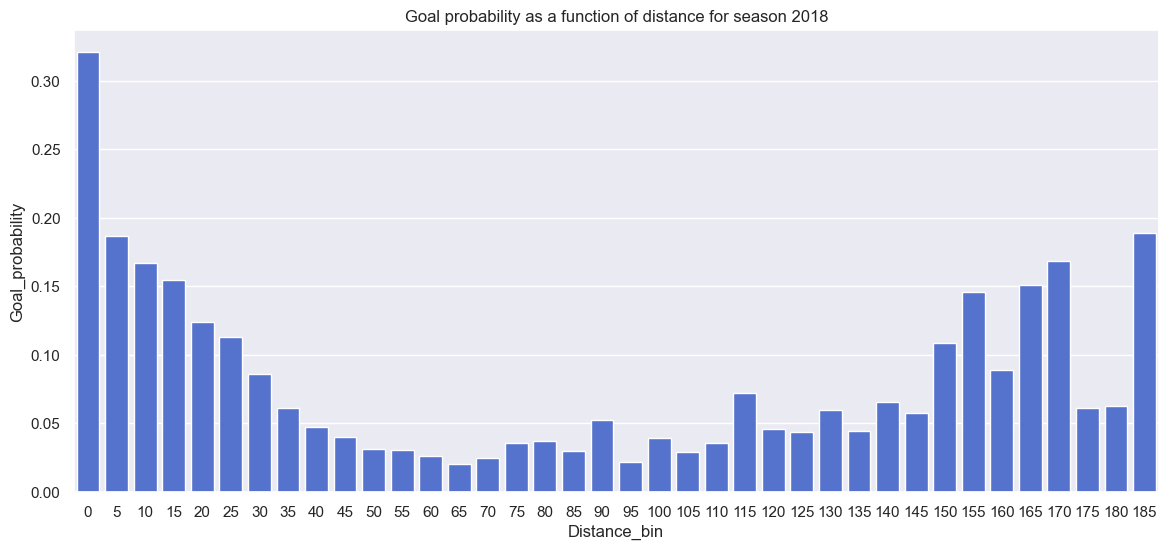

In [66]:
generate_goal_probability_graph(2018)

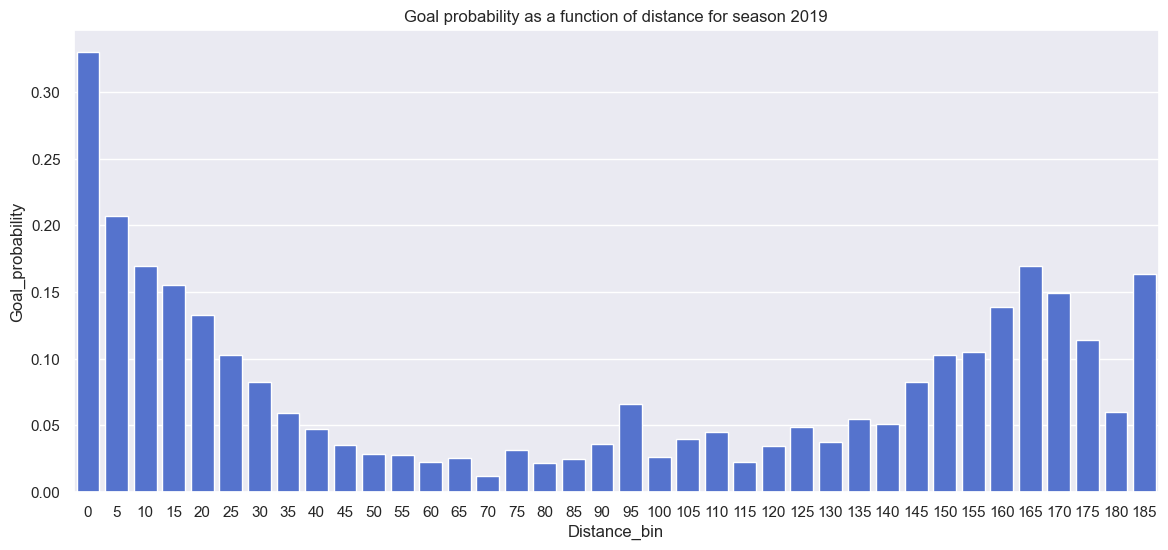

In [67]:
generate_goal_probability_graph(2019)

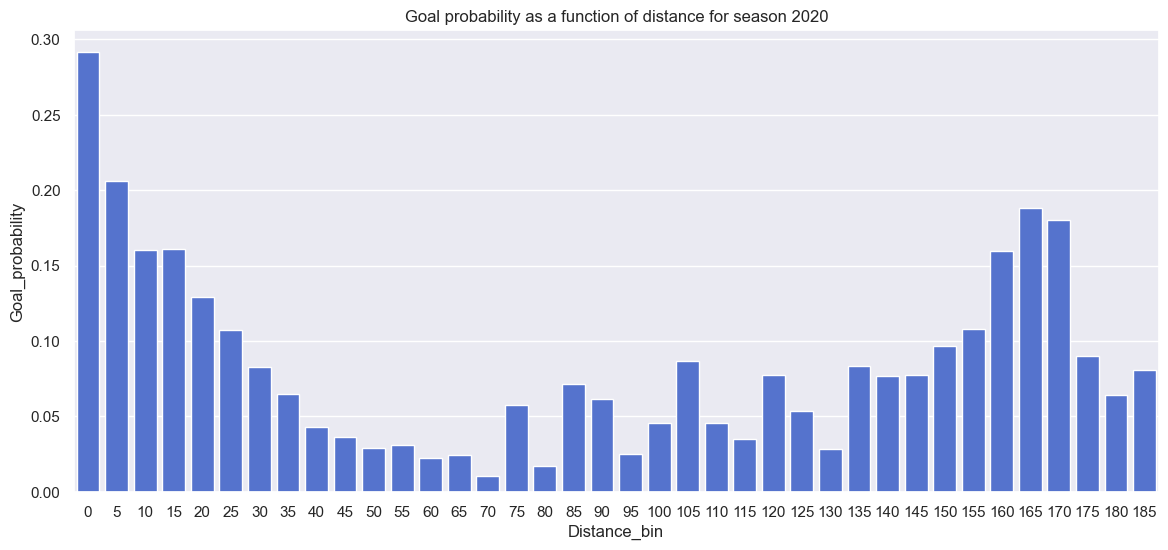

In [68]:
generate_goal_probability_graph(2020)